SVM CLASSIFICATION USING IRIS DATASETS

Dataset Shape: (150, 6)

First 5 Rows:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa



Training Samples: 120
Testing Samples: 30

SVM Accuracy:
96.67%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



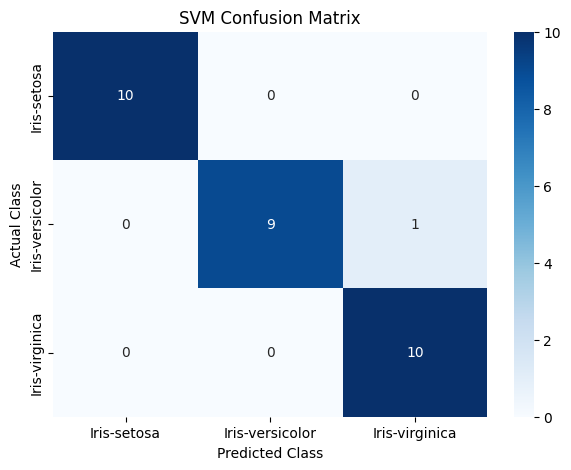


Number of total Support Vectors: 47
Support vectors per Class: [10 18 19]

New Flower:
Sepal Length=5.1
Sepal Width=3.5
Petal Length=1.4
Petal Width=0.2

Predicted Species: Iris-setosa


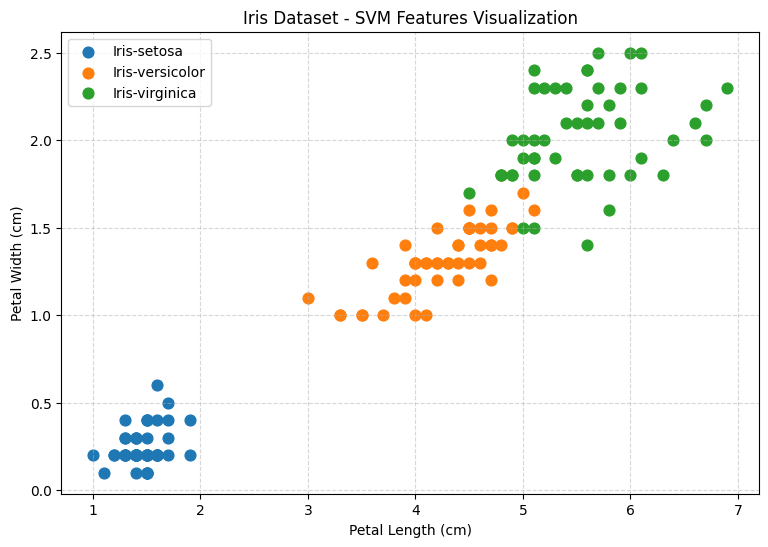


SVM PROJECT COMPLETED SUCCESSFULLY


In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load Dataset
path = "/kaggle/input/datasets/uciml/iris/Iris.csv"
iris = pd.read_csv(path)

print("="*60)
print("SVM CLASSIFICATION USING IRIS DATASETS")
print("="*60)
print("\nDataset Shape:", iris.shape)
print("\nFirst 5 Rows:")
display(iris.head())

# Select features and target
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = iris[features]
y = iris["Species"]

# TRAIN-TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create SVM Model
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

# Train Model
svm_model.fit(X_train_scaled, y_train)

# Predictions
y_pred = svm_model.predict(X_test_scaled)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nSVM Accuracy:")
print(f"{accuracy*100:.2f}%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, 
    annot=True, 
    cmap="Blues", 
    fmt="d",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

# Support Vectors
print("\nNumber of total Support Vectors:", sum(svm_model.n_support_))
print("Support vectors per Class:", svm_model.n_support_)

# Predict a new Flower 
new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=features)
new_flower_scaled = scaler.transform(new_flower)
prediction = svm_model.predict(new_flower_scaled)

print("\nNew Flower:")
print("Sepal Length=5.1")
print("Sepal Width=3.5")
print("Petal Length=1.4")
print("Petal Width=0.2")

print("\nPredicted Species:", prediction[0])

# Simple 2D Visualization
plt.figure(figsize=(9,6))

for species in iris["Species"].unique():
    data = iris[iris["Species"] == species]
    plt.scatter(
        data["PetalLengthCm"],
        data["PetalWidthCm"],
        s=60,
        label=species
    )
    
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Dataset - SVM Features Visualization")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("\n"+"="*60)
print("SVM PROJECT COMPLETED SUCCESSFULLY")
print("="*60)